# 04 — River basins of New England

Every river segment in the six New England states, colored by the river basin it drains to (14 HydroBASINS units at Pfafstetter level 5) and sized by Strahler stream order.

Data: [HydroSHEDS](https://www.hydrosheds.org/) (HydroBASINS v1c and HydroRIVERS v1.0) and the US Census Bureau. Made for the [#30DayMapChallenge](https://30daymapchallenge.com/) 2026, day 3: Polygons.

## 1. Imports and fonts 



In [1]:
import geopandas as gpd
from matplotlib.colors import ListedColormap
import pandas as pd
import matplotlib.pyplot as plt
import io
from PIL import Image
from matplotlib import font_manager

font_manager.fontManager.addfont(
    "Fonts/Montserrat-Bold.ttf"
)
font_manager.fontManager.addfont(
    "Fonts/Montserrat-Light.ttf"
)

## 2.  Settings 

In [2]:
# New England bounding box: degrees, minutes, seconds -> decimal degrees (west longitudes are negative)
west_newE = -(73 + 43/60 + 39/3600)
east_newE = -(66 + 56/60 + 59/3600) 
south_newE = (40 + 59/60 + 0/3600)
north_newE = (47 + 27/60 + 35/3600)

ne_box = (west_newE, south_newE, east_newE, north_newE)


basins_path = "data/hybas_na_lev01-12_v1c/hybas_na_lev12_v1c.shp"  # path to the level-12 basins (the bridge to the rivers)
rivers_path = "../03-rivers/data/HydroRIVERS_v10_na_shp"  # rivers reused from map 03
states_path = "../03-rivers/data/cb_2025_us_state_5m"
basins_path_lv5 = "data/hybas_na_lev01-12_v1c/hybas_na_lev05_v1c.shp"

# a palette of colors for the basins
my_colors = ['#fba097', "#f8b287", '#ece7ac', '#c6efbf', '#c4dbf7', "#9766fa", "#f599c2","#edce87",  "#f67d7d", "#caf973", "#3bfbcb", "#4dc57b", "#f97603", "#2253f5"]
my_cmap = ListedColormap(my_colors)
background_color = "#1a1a1a"   
font_family = "Montserrat"
dim_color = "#585757"
land_color = "#2b2b3a"

## 3. Helper functions 



In [3]:
def save_clean_png(fig, path, dpi=200):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight", facecolor=background_color)
    buf.seek(0)
    img = Image.open(buf)
    Image.frombytes(img.mode, img.size, img.tobytes()).save(path, "PNG", optimize=True)
    print("saved", path, img.size)




## 4. Load data

In [4]:
basins = gpd.read_file(basins_path, bbox=ne_box)
rivers = gpd.read_file(rivers_path, bbox=ne_box)
state = gpd.read_file(states_path)
basins_lv5 = gpd.read_file(basins_path_lv5)


## 5. Join and clip

In [5]:
merged = pd.merge(rivers, basins[["HYBAS_ID", "PFAF_ID"]], left_on="HYBAS_L12", right_on="HYBAS_ID",how="left")
ne_states = state[state["STUSPS"].isin(["MA","RI","NH","ME","CT","VT"])]
ne_states = ne_states.to_crs(basins.crs) 
ne_rivers_basins = gpd.clip(merged, ne_states)
ne_basins_lv5 = gpd.clip(basins_lv5, ne_states)


## 6. Choose basins

In [6]:
ne_rivers_basins["PFAF_ID"] = ne_rivers_basins["PFAF_ID"].astype("string")
ne_rivers_basins["PFAF_L5"] = ne_rivers_basins["PFAF_ID"].str[:5]
ne_basins_lv5["PFAF_ID"] = ne_basins_lv5["PFAF_ID"].astype("string")
missing_basins = ne_basins_lv5[~ne_basins_lv5["PFAF_ID"].isin(ne_rivers_basins["PFAF_L5"])]
ne_basins_lv5_final = ne_basins_lv5[ne_basins_lv5["PFAF_ID"].isin(ne_rivers_basins["PFAF_L5"])]


## 7. Check 

In [7]:
print(len(merged))                              # expected: 24339 (all rivers in the box, before the clip)
print(merged["PFAF_ID"].isna().sum())           # expected: 0 (every river found its basin)
print(len(ne_rivers_basins))                    # expected: 15819 (after the clip)
print(ne_rivers_basins["PFAF_L5"].nunique())    # expected: 14 level-5 basins with rivers
print(missing_basins["PFAF_ID"].tolist())       # expected: ['72510'] (a sliver in Canada, no rivers)
print(len(ne_basins_lv5_final))                 # expected: 14 basins drawn on the map

24339
0
15819
14
['72510']
14


## 8. Plot

Text(0.55, 0.33, '14 river basins · coloured by Pfafstetter level 5')

findfont: Failed to find font weight light for Montserrat, now using 300.


findfont: Failed to find font weight light for Montserrat, now using 300.


findfont: Failed to find font weight light for Montserrat, now using 300.


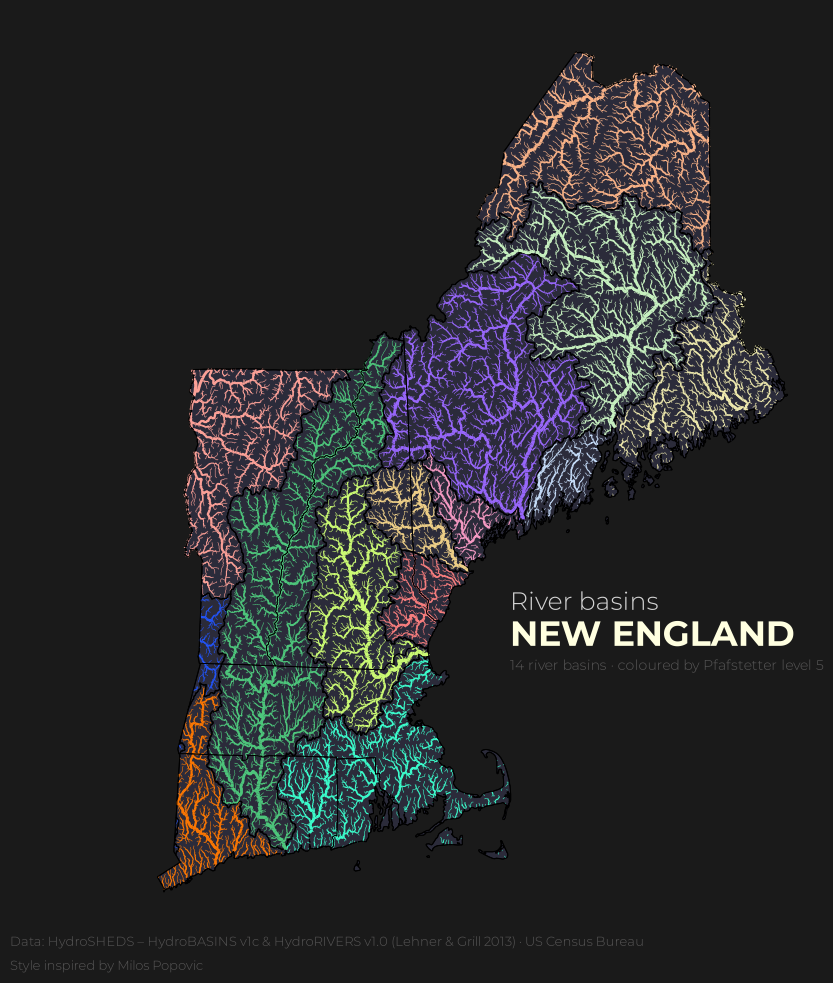

In [8]:
fig, ax = plt.subplots(figsize=(10, 12))
ax.set_axis_off()

fig.set_facecolor(background_color)
ax.set_facecolor(background_color)
ne_states.plot(color=land_color, linewidth=0.3, ax=ax)
ne_basins_lv5_final.boundary.plot(color="black", linewidth=0.8, ax=ax)
ne_rivers_basins.plot(column="PFAF_L5", cmap=my_cmap, linewidth=ne_rivers_basins["ORD_STRA"]*0.4, categorical=True, ax=ax)
ne_states.boundary.plot(color="black", linewidth=0.6, ax=ax)
fig.text(0.55, 0.38, "River basins", color="lightgray", fontfamily=font_family, fontweight="light", fontsize=18)
fig.text(0.55, 0.35, "NEW ENGLAND", color="lightyellow", fontfamily=font_family, fontweight="bold",fontsize=25)
fig.text(0.05, 0.1, "Data: HydroSHEDS – HydroBASINS v1c & HydroRIVERS v1.0 (Lehner & Grill 2013) · US Census Bureau", color=dim_color, fontfamily=font_family, fontweight="light", fontsize=9)
fig.text(0.05, 0.08, "Style inspired by Milos Popovic", color=dim_color, fontfamily=font_family, fontweight="light", fontsize=9)
fig.text(0.55, 0.33, "14 river basins · coloured by Pfafstetter level 5", color=dim_color, fontfamily=font_family, fontweight="light", fontsize=10)

In [9]:
save_clean_png(fig, "ne_basins.png", dpi=300)

saved ne_basins.png (2487, 2949)
